# Avaliação do sistema de respostas

Mede o sistema montado na etapa 6 com perguntas novas, que não foram usadas para ajustar nada. Os testes da etapa 6 serviram para construir; aqui, o conjunto de perguntas e o gabarito são escritos antes de rodar e não mudam depois do resultado. Cada pergunta roda três vezes, porque o modelo varia de uma execução para outra.

| Passo | O que é | Decisões |
|---|---|---|
| 1 | o fluxo da etapa 6, importado de `src/fluxo.py` | D-029, D-030 |
| 2 | conjunto de avaliação: 25 perguntas e gabarito | D-030 |
| 3 | execução: cada pergunta, três vezes | D-030 |
| 4 | métricas automáticas: interpretação, estabilidade, recusas, citações, números, custo | D-030 |
| 5 | fundamentação: juiz automático e julgamento manual de uma amostra | D-030 |
| 6 | painel com os resultados | D-030 |

Os critérios seguem o enunciado (p. 10): recuperar conteúdos relevantes, gerar respostas coerentes com as evidências, evitar informações não fundamentadas, permitir a rastreabilidade e reconhecer quando não há informação suficiente.

📌 Entradas: `src/fluxo.py` (e, por ele, a base etiquetada e o índice de busca).

📌 Saídas: `images/avaliacao/painel_avaliacao.png`, `reports/avaliacao/avaliacao_execucoes.csv`, `reports/avaliacao/avaliacao_julgamentos.csv`; fora do repositório, `data/processed/registro_avaliacao.jsonl` e as execuções e os julgamentos gravados (`.pkl`).

## 1. O fluxo da etapa 6

O código aprovado no desenv_06 foi reunido em `src/fluxo.py`, sem mudança de lógica: as células de teste e de exibição ficaram no notebook. Este notebook e a aplicação (etapa 8) importam o mesmo grafo. O registro das respostas da avaliação vai para um arquivo próprio, separado do registro do desenv_06.

In [1]:
import sys
from pathlib import Path

import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))  # permite importar o código de src/
from src import fluxo  # carrega a base, as etiquetas, o índice e monta o grafo

# o registro da avaliação fica separado do registro do desenv_06
fluxo.ARQUIVO_REGISTRO = RAIZ / "data" / "processed" / "registro_avaliacao.jsonl"

print(f"comentários na base: {fluxo.TOTAL:,}".replace(",", ".") + f" | modelo: {fluxo.MODELO} | "
      f"nós do grafo: {len(fluxo.fluxo.get_graph().nodes) - 2}")

comentários na base: 40.518 | modelo: gemini-3.5-flash-lite | nós do grafo: 10


## 2. Conjunto de avaliação

São 25 perguntas novas, em sete grupos. Três delas são as perguntas do contexto do enunciado (p. 4), que não foram usadas nos ajustes da etapa 6. Cada pergunta tem um gabarito com o que o sistema deveria fazer: o tipo, a faixa do recorte e, quando é consulta ou busca, a medida, o agrupamento e o recorte esperados.

| Grupo | Perguntas | O que testa |
|---|---|---|
| ranking e tema | 6 | queixas e elogios, gerais e dentro de um tema |
| metadados | 5 | região e período, estado, nota, categoria, situação da entrega |
| medidas e comparação | 3 | nota média, prazo por região, valor de dois grupos |
| padrões e evolução | 2 | série mensal e pares de etiquetas |
| busca direta | 3 | pedidos explícitos de avaliações |
| amostra pequena | 2 | recortes de 1 a 29 comentários |
| recusa | 4 | fora do tema, sem dado (2) e recorte vazio |

Quando mais de uma leitura é razoável, o gabarito aceita as alternativas: "principais motivos de insatisfação" pode ser agrupado por tema ou por detalhe. O recorte conta como igual quando seleciona os mesmos comentários, mesmo escrito de outro jeito. A célula confere o próprio gabarito: os recortes existem e as faixas batem com o tamanho real na base.

In [2]:
# ── O conjunto de avaliação: pergunta + gabarito, escrito antes de rodar ─────
# Campos do gabarito (só os que existem são conferidos):
#   tipo         consulta, busca, fora_do_tema ou sem_dado
#   faixa        completo, pequeno ou vazio (tamanho do recorte, passo 5 do desenv_06)
#   medida       a medida da consulta
#   agrupar_por  um agrupamento ou uma lista de agrupamentos aceitos
#   recorte      lista de filtros aceitos; vale o que seleciona os mesmos comentários (passo 4 do desenv_06)
#   comparar_com filtros do segundo grupo
NEG, POS = "negativo", "positivo"
ATRASOS = ["atraso de 1 a 7 dias", "atraso acima de 7 dias"]

CONJUNTO = [
    # ranking e tema (3 delas são as perguntas do contexto do enunciado, p. 4, nunca usadas nos ajustes)
    ("ranking e tema", "Quais são os principais motivos de insatisfação dos clientes?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": ["detalhe", "tema"], "recorte": [{"sentido": NEG}]}),
    ("ranking e tema", "Quais problemas aparecem com maior frequência nas avaliações?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": ["detalhe", "tema"], "recorte": [{"sentido": NEG}]}),
    ("ranking e tema", "O que os consumidores mais valorizam em sua experiência?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": ["detalhe", "tema"], "recorte": [{"sentido": POS}]}),
    ("ranking e tema", "O que mais irrita os clientes no atendimento?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "detalhe", "recorte": [{"sentido": NEG, "tema": ["atendimento"]}]}),
    ("ranking e tema", "Quais são os elogios mais comuns sobre os produtos?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "detalhe", "recorte": [{"sentido": POS, "tema": ["produto"]}]}),
    ("ranking e tema", "Quais reclamações sobre preço aparecem nas avaliações?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "detalhe", "recorte": [{"sentido": NEG, "tema": ["preço"]}]}),
    # metadados
    ("metadados", "O que reclamam os clientes da região Sul em 2018?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": ["detalhe", "tema"],
      "recorte": [{"sentido": NEG, "regiao": ["Sul"], "periodo": ("2018-01", "2018-12")}]}),
    ("metadados", "Quais problemas de entrega os clientes de São Paulo mais relatam?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "detalhe",
      "recorte": [{"sentido": NEG, "tema": ["entrega"], "estado": ["SP"]}]}),
    ("metadados", "O que os clientes que deram nota 5 mais elogiam?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "detalhe", "recorte": [{"sentido": POS, "nota": [5]}]}),
    ("metadados", "Quais são as queixas mais comuns na categoria informática e acessórios?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "detalhe",
      "recorte": [{"sentido": NEG, "categoria": ["informatica acessorios"]}]}),
    ("metadados", "Do que mais reclamam os clientes cuja entrega chegou atrasada?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "detalhe",
      "recorte": [{"sentido": NEG, "faixa_atraso": ATRASOS}]}),
    # medidas e comparação
    ("medidas e comparação", "Qual a nota média dos clientes que reclamam de atraso na entrega?",
     {"tipo": "consulta", "faixa": "completo", "medida": "nota", "agrupar_por": None,
      "recorte": [{"etiqueta": ["negativo · entrega · prazo"]}]}),
    ("medidas e comparação", "Qual o prazo médio de entrega em cada região?",
     {"tipo": "consulta", "faixa": "completo", "medida": "prazo_entrega_dias", "agrupar_por": "regiao", "recorte": [{}]}),
    ("medidas e comparação", "Quem reclama da qualidade do produto gastou mais do que quem elogia a qualidade?",
     {"tipo": "consulta", "faixa": "completo", "medida": "valor_produtos", "agrupar_por": None,
      "recorte": [{"etiqueta": ["negativo · produto · qualidade"]}], "comparar_com": {"etiqueta": ["positivo · produto · qualidade"]}}),
    # padrões e evolução
    ("padrões e evolução", "Como evoluíram os elogios à entrega mês a mês em 2017?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "mes",
      "recorte": [{"sentido": POS, "tema": ["entrega"], "periodo": ("2017-01", "2017-12")}]}),
    ("padrões e evolução", "Quais problemas costumam aparecer juntos nas reclamações sobre atendimento?",
     {"tipo": "consulta", "faixa": "completo", "medida": "comentarios", "agrupar_por": "etiquetas_juntas",
      "recorte": [{"sentido": NEG, "tema": ["atendimento"]}, {"sentido": NEG}]}),
    # busca direta
    ("busca direta", "Mostre avaliações de clientes que receberam um produto diferente do anunciado.",
     {"tipo": "busca", "faixa": "completo", "recorte": [{"etiqueta": ["negativo · produto · conformidade com o anúncio"]}]}),
    ("busca direta", "Quais avaliações mostram clientes que precisaram retirar a encomenda na agência dos Correios?",
     {"tipo": "busca", "faixa": "completo", "recorte": [{"etiqueta": ["negativo · entrega · retirada na agência"]}]}),
    ("busca direta", "Me mostre exemplos de elogios ao atendimento.",
     {"tipo": "busca", "faixa": "completo",
      "recorte": [{"sentido": POS, "tema": ["atendimento"]}, {"etiqueta": ["positivo · atendimento · contato e resposta"]}]}),
    # amostra pequena (recortes de 1 a 29 comentários, conferidos na base)
    ("amostra pequena", "O que os clientes elogiam no frete?",
     {"tipo": "consulta", "faixa": "pequeno", "medida": "comentarios", "recorte": [{"sentido": POS, "tema": ["preço"], "detalhe": ["frete"]}]}),
    ("amostra pequena", "O que os clientes de Roraima reclamam da entrega?",
     {"tipo": "consulta", "faixa": "pequeno", "medida": "comentarios", "recorte": [{"sentido": NEG, "tema": ["entrega"], "estado": ["RR"]}]}),
    # recusas
    ("recusa", "Qual a previsão do tempo para São Paulo amanhã?", {"tipo": "fora_do_tema"}),
    ("recusa", "Qual a idade média dos clientes que reclamam do atendimento?", {"tipo": "sem_dado"}),
    ("recusa", "Quais transportadoras atrasam mais as entregas?", {"tipo": "sem_dado"}),
    ("recusa", "Quais as queixas sobre nota fiscal dos clientes do Acre em 2017?",
     {"tipo": "consulta", "faixa": "vazio", "recorte": [{"sentido": NEG, "detalhe": ["nota fiscal"], "estado": ["AC"], "periodo": ("2017-01", "2017-12")}]}),
]

# conferência do próprio gabarito: os recortes existem e as faixas batem com o tamanho real
linhas = []
for grupo, pergunta, g in CONJUNTO:
    tamanho = len(fluxo.busca.permitidos(g["recorte"][0])) if "recorte" in g else None
    if g.get("medida") == "dias_atraso":
        tamanho = None
    faixa_real = fluxo.faixa_do_recorte(tamanho) if tamanho is not None else None
    if "faixa" in g and g.get("comparar_com") is None:
        assert faixa_real == g["faixa"], (pergunta, tamanho, g["faixa"])
    linhas.append({"grupo": grupo, "pergunta": pergunta, "tipo": g["tipo"], "faixa": g.get("faixa", "-"),
                   "comentários no recorte": tamanho if tamanho is not None else "-",
                   "medida": g.get("medida", "-"), "agrupar_por": g.get("agrupar_por", "-"),
                   "recorte esperado": g.get("recorte", ["-"])[0]})
tabela_conjunto = pd.DataFrame(linhas)
print(f"{len(CONJUNTO)} perguntas:", tabela_conjunto["grupo"].value_counts().to_dict())
with pd.option_context("display.max_colwidth", None):
    display(tabela_conjunto)

25 perguntas: {'ranking e tema': 6, 'metadados': 5, 'recusa': 4, 'medidas e comparação': 3, 'busca direta': 3, 'padrões e evolução': 2, 'amostra pequena': 2}


,grupo,pergunta,tipo,faixa,comentários no recorte,medida,agrupar_por,recorte esperado
0,ranking e tema,Quais são os principais motivos de insatisfação dos clientes?,consulta,completo,15969,comentarios,"[detalhe, tema]",{'sentido': 'negativo'}
1,ranking e tema,Quais problemas aparecem com maior frequência nas avaliações?,consulta,completo,15969,comentarios,"[detalhe, tema]",{'sentido': 'negativo'}
2,ranking e tema,O que os consumidores mais valorizam em sua experiência?,consulta,completo,26425,comentarios,"[detalhe, tema]",{'sentido': 'positivo'}
3,ranking e tema,O que mais irrita os clientes no atendimento?,consulta,completo,3431,comentarios,detalhe,"{'sentido': 'negativo', 'tema': ['atendimento']}"
4,ranking e tema,Quais são os elogios mais comuns sobre os produtos?,consulta,completo,11077,comentarios,detalhe,"{'sentido': 'positivo', 'tema': ['produto']}"
5,ranking e tema,Quais reclamações sobre preço aparecem nas avaliações?,consulta,completo,679,comentarios,detalhe,"{'sentido': 'negativo', 'tema': ['preço']}"
6,metadados,O que reclamam os clientes da região Sul em 2018?,consulta,completo,1183,comentarios,"[detalhe, tema]","{'sentido': 'negativo', 'regiao': ['Sul'], 'periodo': ('2018-01', '2018-12')}"
7,metadados,Quais problemas de entrega os clientes de São Paulo mais relatam?,consulta,completo,3256,comentarios,detalhe,"{'sentido': 'negativo', 'tema': ['entrega'], 'estado': ['SP']}"
8,metadados,O que os clientes que deram nota 5 mais elogiam?,consulta,completo,19427,comentarios,detalhe,"{'sentido': 'positivo', 'nota': [5]}"
9,metadados,Quais são as queixas mais comuns na categoria informática e acessórios?,consulta,completo,1170,comentarios,detalhe,"{'sentido': 'negativo', 'categoria': ['informatica acessorios']}"


**Leitura.** O gabarito passou na própria conferência: os recortes esperados vão de 9 comentários (queixas de entrega em Roraima) a 40.518 (base inteira, prazo por região), as duas amostras pequenas têm 19 e 9 comentários, e o recorte vazio (nota fiscal no Acre em 2017) tem zero.

## 3. Execução: cada pergunta, três vezes

As 25 perguntas passam pelo grafo inteiro três vezes, quatro execuções ao mesmo tempo. De cada execução fica guardado o que a avaliação usa: a interpretação, o tamanho e a faixa do recorte, a recusa, o contexto enviado ao modelo, a resposta, as conferências, os nós percorridos, os tokens e o tempo. As execuções são gravadas em `data/processed/avaliacao_execucoes.pkl`; rodar o notebook de novo lê o arquivo em vez de refazer as chamadas pagas.

In [3]:
import pickle
import time
from concurrent.futures import ThreadPoolExecutor

RODADAS = 3
ARQUIVO_EXECUCOES = RAIZ / "data" / "processed" / "avaliacao_execucoes.pkl"


def executar_caso(caso):
    """Uma pergunta, uma rodada: roda o grafo inteiro e guarda o que a avaliação precisa."""
    numero, rodada = caso
    grupo, pergunta, gabarito = CONJUNTO[numero]
    comeco = time.perf_counter()
    try:
        estado, erro = fluxo.responder(pergunta), None
    except Exception as falha:  # uma falha não derruba as outras execuções; fica registrada
        estado, erro = {}, repr(falha)[:300]
    interp = estado.get("interpretacao")
    tokens = estado.get("tokens", [])
    return {
        "numero": numero + 1, "grupo": grupo, "pergunta": pergunta, "rodada": rodada, "erro": erro,
        "interpretacao": interp.model_dump(mode="json") if interp else None,
        "obtido": fluxo.resumo(interp),               # tipo, medida, agrupamento e filtros, como no passo 4 do desenv_06
        "tamanho": estado.get("tamanho"), "faixa": estado.get("faixa"), "recusa": estado.get("recusa"),
        "contexto": estado.get("contexto"),           # o que o modelo recebeu na redação (usado pelo juiz no passo 5)
        "resposta": estado.get("resposta"), "resposta_final": estado.get("resposta_final"),
        "comentarios": estado["comentarios"]["review_id"].tolist() if estado.get("comentarios") is not None else [],
        "citacoes_invalidas": estado.get("citacoes_invalidas", []), "numeros_fora": estado.get("numeros_fora", []),
        "tentativas_redacao": estado.get("tentativas_redacao", 0),
        "nos": [linha["nó"] for linha in estado.get("rastro", [])],
        "tokens_entrada": sum(e for e, _ in tokens), "tokens_saida": sum(s for _, s in tokens),
        "segundos": round(time.perf_counter() - comeco, 1),
    }


# as execuções ficam gravadas: rodar o notebook de novo não refaz as chamadas pagas
perguntas = [pergunta for _, pergunta, _ in CONJUNTO]
if ARQUIVO_EXECUCOES.exists() and pickle.loads(ARQUIVO_EXECUCOES.read_bytes())["perguntas"] == perguntas:
    execucoes = pickle.loads(ARQUIVO_EXECUCOES.read_bytes())["execucoes"]
    print(f"execuções lidas do arquivo gravado: {len(execucoes)}")
else:
    fluxo.ARQUIVO_REGISTRO.unlink(missing_ok=True)
    casos = [(numero, rodada) for rodada in range(1, RODADAS + 1) for numero in range(len(CONJUNTO))]
    comeco = time.perf_counter()
    with ThreadPoolExecutor(max_workers=4) as executor:  # 4 perguntas ao mesmo tempo
        execucoes = list(executor.map(executar_caso, casos))
    ARQUIVO_EXECUCOES.write_bytes(pickle.dumps({"perguntas": perguntas, "execucoes": execucoes}))
    print(f"{len(execucoes)} execuções em {time.perf_counter() - comeco:.0f} s")

execucoes = pd.DataFrame(execucoes)
custo = (execucoes["tokens_entrada"].sum() * fluxo.PRECO["entrada"] + execucoes["tokens_saida"].sum() * fluxo.PRECO["saida"]) / 1e6
display(pd.Series(dtype=object, data={
    "execuções (25 perguntas × 3 rodadas)": len(execucoes),
    "execuções com erro": int(execucoes["erro"].notna().sum()),
    "tempo por execução (mediana, s)": execucoes["segundos"].median(),
    "custo total (US$)": round(custo, 4),
    "custo por execução (US$)": round(custo / len(execucoes), 5),
}).to_frame("valor"))

execuções lidas do arquivo gravado: 75


,valor
execuções (25 perguntas × 3 rodadas),75
execuções com erro,0
"tempo por execução (mediana, s)",5.0
custo total (US$),0.1018
custo por execução (US$),0.00136


**Leitura.** As 75 execuções rodaram sem erro, em 84 segundos com quatro de cada vez.

## 4. Métricas automáticas

Cada execução é comparada com o gabarito, campo a campo. Um critério só conta onde se aplica: o recorte não é conferido numa pergunta fora do tema, e as citações só são conferidas quando houve resposta escrita.

| Critério | Pergunta que responde | Critério do enunciado |
|---|---|---|
| interpretação | o formulário preenchido é o esperado? | recuperar conteúdos relevantes |
| recusa certa | recusou quando devia, e só quando devia? | reconhecer quando não há informação suficiente |
| faixa | separou recorte completo, pequeno e vazio? | reconhecer quando não há informação suficiente |
| citações válidas | toda citação existe entre os comentários entregues? | gerar respostas coerentes com as evidências |
| números no contexto | todo número da resposta está na tabela, no recorte ou nos comentários? | evitar informações não fundamentadas |
| estabilidade | as três rodadas chegaram ao mesmo formulário? | (critério do projeto: o modelo varia entre execuções) |

A busca em si foi medida na etapa 5 (D-028): 96% dos comentários trazidos tinham a etiqueta do assunto pedido.

In [4]:
RECUSA_ESPERADA = {"fora_do_tema": "fora do tema", "sem_dado": "no tema, sem dado"}


def conferir_execucao(linha):
    """Compara uma execução com o gabarito, campo a campo. None = campo não se aplica."""
    gabarito = CONJUNTO[linha["numero"] - 1][2]
    obtido = linha["obtido"]
    r = {}
    r["tipo"] = obtido["tipo"] == gabarito["tipo"]
    if "medida" in gabarito:
        r["medida"] = obtido.get("medida") == gabarito["medida"]
    if "agrupar_por" in gabarito:
        aceitos = gabarito["agrupar_por"] if isinstance(gabarito["agrupar_por"], list) else [gabarito["agrupar_por"]]
        r["agrupamento"] = obtido.get("agrupar_por") in aceitos
    if "recorte" in gabarito:
        # vale qualquer recorte aceito que selecione os mesmos comentários
        r["recorte"] = any(fluxo.mesmo_recorte(alternativa, obtido.get("filtros")) for alternativa in gabarito["recorte"])
    if "comparar_com" in gabarito:
        r["recorte"] = r["recorte"] and fluxo.mesmo_recorte(gabarito["comparar_com"], obtido.get("comparar_com"))
    r["interpretação"] = all(r.values())  # todos os campos do formulário certos
    # recusa: as esperadas acontecem, e nenhuma pergunta respondível é recusada
    if gabarito["tipo"] in RECUSA_ESPERADA:
        r["recusa certa"] = linha["recusa"] == RECUSA_ESPERADA[gabarito["tipo"]]
    elif gabarito.get("faixa") == "vazio":
        r["recusa certa"] = linha["recusa"] == "recorte vazio"
    else:
        r["recusa certa"] = pd.isna(linha["recusa"])  # sem recusa (no DataFrame, o vazio vira NaN)
    if "faixa" in gabarito:
        r["faixa"] = linha["faixa"] == gabarito["faixa"]
    # conferências da resposta (só quando houve resposta escrita pelo modelo)
    if linha["resposta"] is not None:
        r["citações válidas"] = not [n for n in linha["citacoes_invalidas"] if n != 0]
        r["cita comentários"] = 0 not in linha["citacoes_invalidas"]
        r["números no contexto"] = not linha["numeros_fora"]
    return pd.Series(r, dtype=object)


conferencia = execucoes.apply(conferir_execucao, axis=1)
avaliadas = pd.concat([execucoes[["numero", "grupo", "pergunta", "rodada"]], conferencia], axis=1)


def taxa(coluna, dados=avaliadas):
    """Percentual de acerto entre as execuções em que o critério se aplica."""
    valores = dados[coluna].dropna().astype(bool)
    return valores.mean() if len(valores) else None


# ── estabilidade: as 3 rodadas da mesma pergunta chegaram ao mesmo formulário? ──
def assinatura(obtido):
    """O que define o caminho: tipo, medida, agrupamento e os comentários do recorte."""
    filtros = obtido.get("filtros")
    recorte = tuple(fluxo.busca.permitidos(filtros)[:50]) + (len(fluxo.busca.permitidos(filtros)),) if filtros is not None else None
    comparar = obtido.get("comparar_com")
    return (obtido["tipo"], obtido.get("medida"), obtido.get("agrupar_por"), recorte,
            len(fluxo.busca.permitidos(comparar)) if comparar is not None else None)


estabilidade = execucoes.groupby("numero")["obtido"].apply(lambda serie: serie.map(assinatura).nunique() == 1)

# ── tabela-resumo por critério ──
CRITERIOS = {
    "interpretação": "formulário igual ao gabarito (tipo, medida, agrupamento e recorte)",
    "tipo": "tipo da pergunta certo (consulta, busca, fora do tema, sem dado)",
    "recorte": "recorte seleciona os comentários esperados",
    "recusa certa": "recusa quando devia e só quando devia",
    "faixa": "faixa do recorte certa (completo, pequeno, vazio)",
    "citações válidas": "toda citação existe na lista entregue ao modelo",
    "cita comentários": "a resposta cita ao menos um comentário",
    "números no contexto": "todo número da resposta aparece no contexto",
}
resumo_criterios = pd.DataFrame([{"critério": c, "o que mede": d, "execuções": int(avaliadas[c].notna().sum()),
                                  "acerto": taxa(c)} for c, d in CRITERIOS.items()])
resumo_criterios.loc[len(resumo_criterios)] = {"critério": "estabilidade", "o que mede": "as 3 rodadas da pergunta chegam ao mesmo formulário",
                                               "execuções": len(estabilidade), "acerto": estabilidade.mean()}
resumo_criterios["acerto"] = resumo_criterios["acerto"].map(lambda v: f"{v:.0%}")
with pd.option_context("display.max_colwidth", None):
    display(resumo_criterios)

# ── por grupo de pergunta ──
por_grupo = avaliadas.groupby("grupo", sort=False).agg(
    execuções=("rodada", "size"),
    interpretação=("interpretação", lambda s: s.astype(bool).mean()),
    recusa_certa=("recusa certa", lambda s: s.astype(bool).mean()))
grupo_da_pergunta = execucoes.drop_duplicates("numero").set_index("numero")["grupo"]
por_grupo["estabilidade"] = estabilidade.groupby(grupo_da_pergunta).mean()
display(por_grupo.style.format({c: "{:.0%}" for c in ("interpretação", "recusa_certa", "estabilidade")}))

# ── as execuções que erraram algum critério, com o que veio ──
colunas = [c for c in CRITERIOS if c in avaliadas]
falhas = avaliadas[~avaliadas[colunas].apply(lambda linha: all(v is None or pd.isna(v) or bool(v) for v in linha), axis=1)]
detalhe_falhas = falhas[["numero", "pergunta", "rodada"]].assign(
    criterios=falhas[colunas].apply(lambda l: ", ".join(c for c in colunas if l[c] is not None and not pd.isna(l[c]) and not bool(l[c])), axis=1),
    veio=execucoes.loc[falhas.index, "obtido"].map(lambda o: {k: v for k, v in o.items() if v not in (None, {})}),
    recusa=execucoes.loc[falhas.index, "recusa"])
print(f"execuções com algum critério errado: {len(falhas)} de {len(avaliadas)}")
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(detalhe_falhas)

,critério,o que mede,execuções,acerto
0,interpretação,"formulário igual ao gabarito (tipo, medida, agrupamento e recorte)",75,96%
1,tipo,"tipo da pergunta certo (consulta, busca, fora do tema, sem dado)",75,99%
2,recorte,recorte seleciona os comentários esperados,66,95%
3,recusa certa,recusa quando devia e só quando devia,75,99%
4,faixa,"faixa do recorte certa (completo, pequeno, vazio)",66,98%
5,citações válidas,toda citação existe na lista entregue ao modelo,75,100%
6,cita comentários,a resposta cita ao menos um comentário,75,100%
7,números no contexto,todo número da resposta aparece no contexto,75,100%
8,estabilidade,as 3 rodadas da pergunta chegam ao mesmo formulário,25,96%


,execuções,interpretação,recusa_certa,estabilidade
grupo,,,,
ranking e tema,18,100%,100%,100%
metadados,15,100%,100%,100%
medidas e comparação,9,67%,89%,67%
padrões e evolução,6,100%,100%,100%
busca direta,9,100%,100%,100%
amostra pequena,6,100%,100%,100%
recusa,12,100%,100%,100%


execuções com algum critério errado: 3 de 75


,numero,pergunta,rodada,criterios,veio,recusa
13,14,Quem reclama da qualidade do produto gastou mais do que quem elogia a qualidade?,1,"interpretação, recorte","{'tipo': 'consulta', 'medida': 'valor_produtos', 'agrupar_por': 'sentido', 'filtros': {'tema': ['produto'], 'detalhe': ['qualidade']}}",NaN
38,14,Quem reclama da qualidade do produto gastou mais do que quem elogia a qualidade?,2,"interpretação, recorte","{'tipo': 'consulta', 'medida': 'valor_produtos', 'agrupar_por': 'sentido', 'filtros': {'tema': ['produto'], 'detalhe': ['qualidade']}}",NaN
63,14,Quem reclama da qualidade do produto gastou mais do que quem elogia a qualidade?,3,"interpretação, tipo, recorte, recusa certa, faixa",{'tipo': 'sem_dado'},"no tema, sem dado"


**Leitura.** Das 75 execuções, 72 acertaram todos os critérios. Os critérios da resposta ficaram em 100%: toda citação existe entre os comentários entregues, toda resposta cita ao menos um comentário e nenhum número da resposta ficou fora do contexto. As recusas esperadas aconteceram nas 12 execuções das perguntas de recusa (fora do tema, sem dado e recorte vazio), e as duas amostras pequenas foram reconhecidas como pequenas nas seis execuções.

As três execuções com erro são da mesma pergunta, a 14 ("quem reclama da qualidade do produto gastou mais do que quem elogia a qualidade?"):

| Rodada | O que veio | Leitura |
|---|---|---|
| 1 e 2 | valor dos produtos agrupado por sentido, dentro de produto · qualidade | caminho diferente do gabarito, com o mesmo resultado: o agrupamento por sentido separa exatamente os dois grupos da comparação |
| 3 | recusa por falta de dado | erro: a base tem o valor dos produtos, e a pergunta tinha resposta |

Pelo gabarito, congelado antes da execução, a interpretação acertou 96% e a estabilidade foi de 96% (24 das 25 perguntas tiveram o mesmo formulário nas três rodadas). Contando o caminho equivalente das rodadas 1 e 2 como certo, a interpretação iria a 99%, mas o gabarito não é alterado depois do resultado; o caso fica registrado. A recusa indevida aconteceu em 1 das 63 execuções de perguntas respondíveis.

As 75 execuções custaram US$ 0,10 (US$ 0,0014 por pergunta), com 5 segundos por resposta (mediana).

## 5. Fundamentação: juiz automático

As métricas do passo 4 conferem a forma da resposta: a citação existe, o número está no contexto. Não conferem o conteúdo: uma resposta pode citar um comentário que existe e atribuir a ele algo que ele não diz, ou inventar uma causa sem nenhum número. Isso exige ler o texto.

Um modelo juiz lê o contexto que o sistema recebeu (recorte, tabela e comentários) e a resposta, separa a resposta em afirmações e julga cada uma: sustentada, parcialmente sustentada (vai além do contexto sem contradizê-lo) ou não sustentada (contradiz o contexto ou inventa). Depois dá duas notas gerais: se a resposta é fundamentada e se responde ao que foi perguntado.

O juiz é o `gemini-3.8-flash`, maior e diferente do modelo que escreve as respostas, para que o modelo não julgue a si mesmo. São julgadas as 21 respostas escritas da rodada 1 (as quatro recusas não têm texto do modelo). Por decisão de prazo, o veredito do juiz é tomado como correto, sem uma amostra julgada à mão para medir a concordância; essa limitação fica registrada na D-030.

In [5]:
from typing import Literal

from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
from pydantic import BaseModel, Field

MODELO_JUIZ = "gemini-3.8-flash"            # maior e diferente do modelo que escreve as respostas
PRECO_JUIZ = {"entrada": 0.75, "saida": 3.75}  # US$ por 1 milhão de tokens
ARQUIVO_JULGAMENTOS = RAIZ / "data" / "processed" / "avaliacao_julgamentos.pkl"
Nivel = Literal["sim", "parcial", "não"]


# ── 1. O formulário do juiz ──────────────────────────────────────────────────
class Afirmacao(BaseModel):
    afirmacao: str = Field(description="uma afirmação da resposta, resumida em poucas palavras")
    sustentada: Nivel = Field(description="sim: o contexto apoia; parcial: vai além do contexto sem contradizê-lo; "
                                          "não: contradiz o contexto ou inventa fato ou número")
    motivo: str = Field(description="por que, em uma frase")


class Julgamento(BaseModel):
    afirmacoes: list[Afirmacao] = Field(description="todas as afirmações da resposta, uma a uma")
    fundamentada: Nivel = Field(description="sim: todas sustentadas; parcial: alguma só parcialmente; não: alguma não sustentada")
    responde_pergunta: Nivel = Field(description="sim: responde ao que foi perguntado; parcial: responde em parte; não: não responde")
    justificativa: str = Field(description="resumo do julgamento em até duas frases")


JUIZ = """Você avalia respostas de um sistema que responde perguntas de gestores sobre avaliações de clientes de e-commerce. \
O sistema calcula os números em código e busca comentários; um modelo de linguagem escreve a resposta a partir disso.

Você recebe a pergunta, o contexto que o modelo recebeu (recorte, tabela calculada e comentários numerados) e a resposta escrita.

Separe a resposta em afirmações e julgue cada uma só pelo contexto:
- sim: a tabela, o recorte ou os comentários citados apoiam a afirmação;
- parcial: a afirmação vai além do contexto sem contradizê-lo (por exemplo, generaliza a partir de poucos comentários);
- não: a afirmação contradiz o contexto, inventa um fato, uma causa ou um número, ou cita um comentário que não diz aquilo.
Avisos de método (percentuais que não somam 100%, amostra pequena) contam como sustentados.
Depois dê a nota geral de fundamentação e diga se a resposta responde ao que foi perguntado."""

prompt_juiz = ChatPromptTemplate.from_messages([("system", JUIZ), ("human", "{entrada}")])
juiz = prompt_juiz | ChatGoogleGenerativeAI(model=MODELO_JUIZ).with_structured_output(Julgamento, include_raw=True)


def julgar(linha):
    """Uma resposta → julgamento, com tempo e tokens."""
    # o contexto sem as instruções de redação: só o que o modelo recebeu como dados (pergunta, recorte, tabela, comentários)
    dados = linha["contexto"].split("Human: ", 1)[1]
    entrada = f"{dados}\n\nResposta escrita pelo sistema:\n{linha['resposta']}"
    comeco = time.perf_counter()
    saida = juiz.invoke({"entrada": entrada})
    uso = saida["raw"].usage_metadata or {}
    return {"numero": linha["numero"], "julgamento": saida["parsed"],
            "erro": str(saida["parsing_error"])[:200] if saida["parsing_error"] else None,
            "segundos": round(time.perf_counter() - comeco, 1),
            "tokens_entrada": uso.get("input_tokens", 0), "tokens_saida": uso.get("output_tokens", 0)}


# ── 2. Julga as respostas escritas da rodada 1 (gravadas para não repetir a chamada) ──
para_julgar = execucoes[(execucoes["rodada"] == 1) & execucoes["resposta"].notna()]
if ARQUIVO_JULGAMENTOS.exists() and pickle.loads(ARQUIVO_JULGAMENTOS.read_bytes())["numeros"] == para_julgar["numero"].tolist():
    julgamentos = pickle.loads(ARQUIVO_JULGAMENTOS.read_bytes())["julgamentos"]
    print(f"julgamentos lidos do arquivo gravado: {len(julgamentos)}")
else:
    comeco = time.perf_counter()
    with ThreadPoolExecutor(max_workers=4) as executor:
        julgamentos = list(executor.map(julgar, [linha for _, linha in para_julgar.iterrows()]))
    ARQUIVO_JULGAMENTOS.write_bytes(pickle.dumps({"numeros": para_julgar["numero"].tolist(), "julgamentos": julgamentos}))
    print(f"{len(julgamentos)} julgamentos em {time.perf_counter() - comeco:.0f} s")

# ── 3. Resultado ─────────────────────────────────────────────────────────────
linhas = []
for j in julgamentos:
    g = j["julgamento"]
    linhas.append({"numero": j["numero"], "pergunta": CONJUNTO[j["numero"] - 1][1],
                   "fundamentada": g.fundamentada if g else "erro", "responde à pergunta": g.responde_pergunta if g else "erro",
                   "afirmações": len(g.afirmacoes) if g else None,
                   "sustentadas": sum(a.sustentada == "sim" for a in g.afirmacoes) if g else None,
                   "parciais": sum(a.sustentada == "parcial" for a in g.afirmacoes) if g else None,
                   "não sustentadas": sum(a.sustentada == "não" for a in g.afirmacoes) if g else None,
                   "segundos": j["segundos"]})
tabela_juiz = pd.DataFrame(linhas)
custo_juiz = sum(j["tokens_entrada"] * PRECO_JUIZ["entrada"] + j["tokens_saida"] * PRECO_JUIZ["saida"] for j in julgamentos) / 1e6
total_afirmacoes = tabela_juiz["afirmações"].sum()
print(f"respostas julgadas: {len(tabela_juiz)} | afirmações: {total_afirmacoes} "
      f"(sustentadas {tabela_juiz['sustentadas'].sum() / total_afirmacoes:.0%}, parciais {tabela_juiz['parciais'].sum() / total_afirmacoes:.0%}, "
      f"não sustentadas {tabela_juiz['não sustentadas'].sum() / total_afirmacoes:.0%}) | "
      f"tempo por julgamento (mediana): {tabela_juiz['segundos'].median():.0f} s | custo: US$ {custo_juiz:.3f}")
display(pd.DataFrame({"fundamentada": tabela_juiz["fundamentada"].value_counts(),
                      "responde à pergunta": tabela_juiz["responde à pergunta"].value_counts()}).fillna(0).astype(int))
with pd.option_context("display.max_colwidth", None):
    display(tabela_juiz.drop(columns="segundos"))

# afirmações que o juiz não considerou sustentadas, com o motivo
pendentes = [{"numero": j["numero"], "afirmação": a.afirmacao, "julgamento": a.sustentada, "motivo": a.motivo}
             for j in julgamentos if j["julgamento"] for a in j["julgamento"].afirmacoes if a.sustentada != "sim"]
print(f"afirmações parciais ou não sustentadas: {len(pendentes)}")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(pendentes))

julgamentos lidos do arquivo gravado: 21
respostas julgadas: 21 | afirmações: 116 (sustentadas 98%, parciais 1%, não sustentadas 1%) | tempo por julgamento (mediana): 12 s | custo: US$ 0.107


,fundamentada,responde à pergunta
não,1,0
parcial,1,1
sim,19,20


,numero,pergunta,fundamentada,responde à pergunta,afirmações,sustentadas,parciais,não sustentadas
0,1,Quais são os principais motivos de insatisfação dos clientes?,sim,sim,6,6,0,0
1,2,Quais problemas aparecem com maior frequência nas avaliações?,sim,sim,6,6,0,0
2,3,O que os consumidores mais valorizam em sua experiência?,sim,sim,5,5,0,0
3,4,O que mais irrita os clientes no atendimento?,sim,sim,5,5,0,0
4,5,Quais são os elogios mais comuns sobre os produtos?,sim,sim,5,5,0,0
5,6,Quais reclamações sobre preço aparecem nas avaliações?,sim,sim,7,7,0,0
6,7,O que reclamam os clientes da região Sul em 2018?,sim,sim,6,6,0,0
7,8,Quais problemas de entrega os clientes de São Paulo mais relatam?,não,sim,6,5,0,1
8,9,O que os clientes que deram nota 5 mais elogiam?,sim,sim,6,6,0,0
9,10,Quais são as queixas mais comuns na categoria informática e acessórios?,sim,sim,4,4,0,0


afirmações parciais ou não sustentadas: 2


,numero,afirmação,julgamento,motivo
0,8,O comentário [6] traz menção à demora na entrega,não,"O comentário [6] relata um produto com defeito que não funcionou nos notebooks, sem mencionar demora ou prazo."
1,18,"As avaliações [1], [2], [3] e [5] mostram insatisfação por precisarem se deslocar até uma agência dos Correios para retirar produtos.",parcial,"Os comentários [1], [3] e [5] mencionam a retirada ou disponibilidade na agência, mas o [2] apenas relata que os Correios costumam encaminhar para a sede sem tentar entregar, sem afirmar explicitamente que o cliente se deslocou para retirar."


**Leitura.** O juiz separou as 21 respostas em 116 afirmações: 114 sustentadas pelo contexto, uma parcial e uma não sustentada. Pela nota geral, 19 respostas são fundamentadas, uma parcialmente e uma não; 20 respondem ao que foi perguntado. Os 21 julgamentos levaram 61 segundos (12 s cada, na mediana) e custaram US$ 0,11.

| Pergunta | O que o juiz apontou | Origem |
|---|---|---|
| 8, problemas de entrega em São Paulo (não fundamentada) | a resposta cita o comentário [6] como exemplo de demora, mas ele fala de um produto que chegou e não funciona | o comentário tem a etiqueta de prazo ("chegou ontem") e foi escolhido como prova desse grupo; o modelo confiou no grupo informado no contexto. Erro de etiquetagem que passou para a resposta |
| 18, retirada na agência (parcial) | um dos comentários fala que os Correios encaminham para a sede, sem dizer que o cliente foi buscar | leitura um pouco além do que o comentário diz |
| 15, elogios à entrega mês a mês (responde em parte) | a resposta comenta o primeiro trimestre e dezembro e pula os outros meses | a resposta resume a série em vez de percorrer todos os meses |

Nenhuma resposta inventou causa, fato ou número. Os dois problemas de fundamentação vêm da relação entre o comentário e o grupo em que ele foi apresentado, e não de informação de fora do contexto.

## 6. Painel com os resultados

O painel reúne as medidas dos passos 4 e 5 nos três blocos de critérios do enunciado: entender a pergunta, reconhecer o limite do que a base responde e responder com evidência. As tabelas por execução e por afirmação ficam em `reports/avaliacao/`.

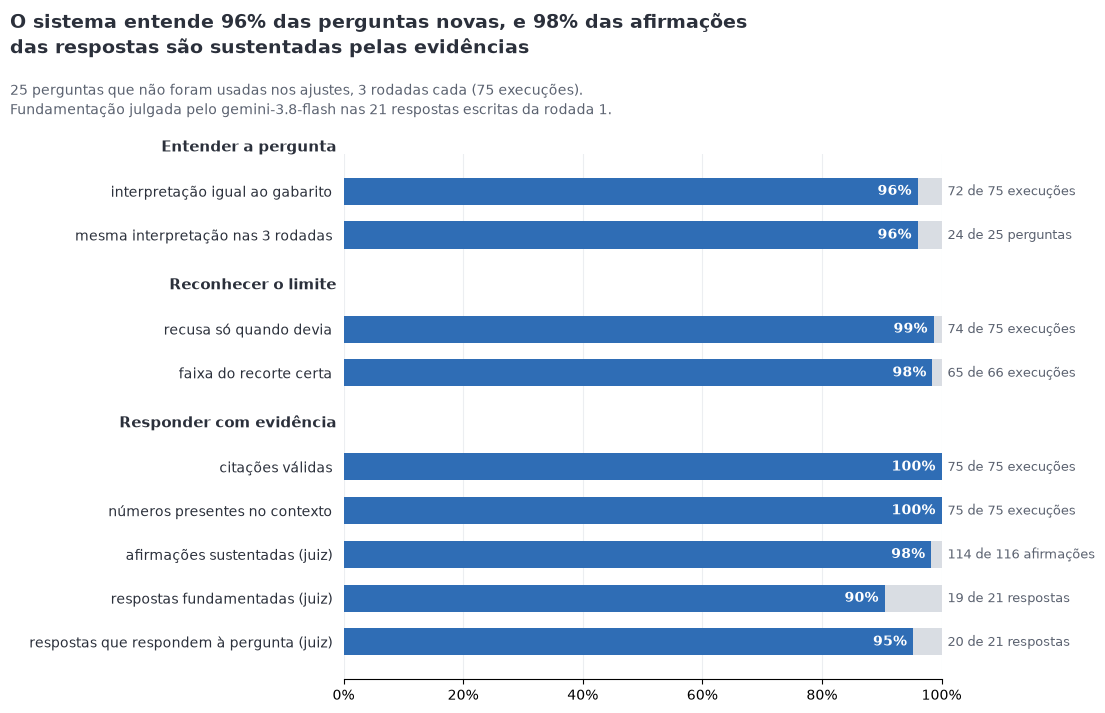

gravados: images\avaliacao\painel_avaliacao.png | reports/avaliacao/avaliacao_execucoes.csv | reports/avaliacao/avaliacao_julgamentos.csv


In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

PASTA_FIGURAS = RAIZ / "images" / "avaliacao"
PASTA_RELATORIOS = RAIZ / "reports" / "avaliacao"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)
PASTA_RELATORIOS.mkdir(parents=True, exist_ok=True)


def contagem(serie):
    """(acertos, total) entre as execuções em que o critério se aplica."""
    valores = serie.dropna().astype(bool)
    return int(valores.sum()), len(valores)


# ── 1. Os números do painel, agrupados pelos critérios do enunciado ─────────
afirmacoes = [a for j in julgamentos if j["julgamento"] for a in j["julgamento"].afirmacoes]
painel = [
    # (bloco, medida, acertos, total, unidade)
    ("Entender a pergunta", "interpretação igual ao gabarito", *contagem(avaliadas["interpretação"]), "execuções"),
    ("Entender a pergunta", "mesma interpretação nas 3 rodadas", int(estabilidade.sum()), len(estabilidade), "perguntas"),
    ("Reconhecer o limite", "recusa só quando devia", *contagem(avaliadas["recusa certa"]), "execuções"),
    ("Reconhecer o limite", "faixa do recorte certa", *contagem(avaliadas["faixa"]), "execuções"),
    ("Responder com evidência", "citações válidas", *contagem(avaliadas["citações válidas"]), "execuções"),
    ("Responder com evidência", "números presentes no contexto", *contagem(avaliadas["números no contexto"]), "execuções"),
    ("Responder com evidência", "afirmações sustentadas (juiz)", sum(a.sustentada == "sim" for a in afirmacoes), len(afirmacoes), "afirmações"),
    ("Responder com evidência", "respostas fundamentadas (juiz)", int((tabela_juiz["fundamentada"] == "sim").sum()), len(tabela_juiz), "respostas"),
    ("Responder com evidência", "respostas que respondem à pergunta (juiz)", int((tabela_juiz["responde à pergunta"] == "sim").sum()), len(tabela_juiz), "respostas"),
]
painel = pd.DataFrame(painel, columns=["bloco", "medida", "acertos", "total", "unidade"])
painel["acerto"] = painel["acertos"] / painel["total"]

# ── 2. Figura ────────────────────────────────────────────────────────────────
AZUL, CINZA, TEXTO = "#2f6db5", "#d9dde3", "#2b303b"
fig, ax = plt.subplots(figsize=(11.5, 7.2))
posicoes, rotulos, y = [], [], 0
for bloco, linhas_bloco in painel.groupby("bloco", sort=False):
    y += 1.15  # uma linha só para o nome do bloco
    ax.text(-0.012, -y, bloco, transform=ax.get_yaxis_transform(), ha="right", va="center",
            fontsize=11, fontweight="bold", color=TEXTO)
    for linha in linhas_bloco.itertuples():
        y += 1
        posicoes.append(-y)
        rotulos.append(linha.medida)
        ax.barh(-y, 1, color=CINZA, height=0.62, zorder=1)                 # trilho: 100%
        ax.barh(-y, linha.acerto, color=AZUL, height=0.62, zorder=2)       # acerto
        ax.text(linha.acerto - 0.01, -y, f"{linha.acerto:.0%}", ha="right", va="center", color="white",
                fontsize=10, fontweight="bold", zorder=3)
        ax.text(1.01, -y, f"{linha.acertos} de {linha.total} {linha.unidade}", ha="left", va="center",
                fontsize=9, color="#5b6270")
ax.set_yticks(posicoes, rotulos, fontsize=10, color=TEXTO)
ax.tick_params(axis="y", length=0, pad=8)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", color="#eceef1", zorder=0)
interpretacao = painel.set_index("medida").loc["interpretação igual ao gabarito", "acerto"]
sustentadas = painel.set_index("medida").loc["afirmações sustentadas (juiz)", "acerto"]
fig.suptitle(f"O sistema entende {interpretacao:.0%} das perguntas novas, e {sustentadas:.0%} das afirmações\n"
             "das respostas são sustentadas pelas evidências", x=0.02, y=0.99, ha="left", fontsize=14,
             fontweight="bold", color=TEXTO, linespacing=1.3)
fig.text(0.02, 0.845, f"25 perguntas que não foram usadas nos ajustes, 3 rodadas cada ({len(execucoes)} execuções).\n"
         f"Fundamentação julgada pelo {MODELO_JUIZ} nas {len(tabela_juiz)} respostas escritas da rodada 1.",
         ha="left", fontsize=10, color="#5b6270", linespacing=1.4)
fig.subplots_adjust(left=0.31, right=0.83, top=0.79, bottom=0.06)
arquivo_figura = PASTA_FIGURAS / "painel_avaliacao.png"
fig.savefig(arquivo_figura, dpi=150)
plt.show()

# ── 3. Tabelas gravadas (versionadas) ────────────────────────────────────────
saida_execucoes = avaliadas.assign(
    tipo_obtido=execucoes["obtido"].map(lambda o: o["tipo"]),
    formulario_obtido=execucoes["obtido"].map(lambda o: str({k: v for k, v in o.items() if k != "tipo"})),
    recusa=execucoes["recusa"], segundos=execucoes["segundos"])
saida_execucoes.to_csv(PASTA_RELATORIOS / "avaliacao_execucoes.csv", index=False, encoding="utf-8-sig")
pd.DataFrame([{"numero": j["numero"], "pergunta": CONJUNTO[j["numero"] - 1][1], "afirmação": a.afirmacao,
               "sustentada": a.sustentada, "motivo": a.motivo}
              for j in julgamentos if j["julgamento"] for a in j["julgamento"].afirmacoes]
             ).to_csv(PASTA_RELATORIOS / "avaliacao_julgamentos.csv", index=False, encoding="utf-8-sig")
print("gravados:", arquivo_figura.relative_to(RAIZ), "| reports/avaliacao/avaliacao_execucoes.csv | reports/avaliacao/avaliacao_julgamentos.csv")

**Leitura.** Nos três blocos do enunciado, o sistema fica entre 90% e 100%:

- **Entender a pergunta.** 96% das execuções chegaram ao formulário do gabarito, e 24 das 25 perguntas tiveram a mesma interpretação nas três rodadas. Os erros estão todos na pergunta de comparação de gasto (14), a única em que o modelo alternou entre caminhos.
- **Reconhecer o limite.** As recusas esperadas aconteceram em todas as execuções, e só uma pergunta respondível foi recusada (99%). As amostras pequenas e o recorte vazio foram reconhecidos.
- **Responder com evidência.** As conferências do código (citações e números) ficaram em 100%. Pelo juiz, 98% das afirmações são sustentadas pelo contexto, e 19 das 21 respostas são fundamentadas.

A fundamentação é a medida com mais espaço para melhorar, e o caso não fundamentado mostra por onde: um comentário com etiqueta errada, apresentado como prova do grupo, levou o modelo a afirmar algo que o comentário não diz. A busca da prova escolhe comentários dentro da etiqueta e confia nela; uma conferência entre o texto do comentário e o grupo, ou mais comentários por grupo, reduziria esse risco.

O resultado vale para estas 25 perguntas e para o juiz automático, cujo veredito foi tomado como correto sem comparação com um julgamento humano (D-030). A avaliação inteira custou US$ 0,21: US$ 0,10 nas 75 execuções e US$ 0,11 no juiz.